# 状态图

在上一节中，我们演示了如何使用 LangGraph 创建 ReAct Agent。但是，把任务交给 Agent 等于把控制权也交了出去。如果你不希望 Agent 拥有如此高的控制权，而是希望流程完全受你控制，那么可以使用 **状态图**（StateGraph）来创建工作流。

In [1]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain.messages import HumanMessage, SystemMessage
from langchain.tools import tool
from langgraph.prebuilt import ToolNode
from langchain_core.runnables import RunnableConfig

# 加载模型配置
_ = load_dotenv()

本节实现了一个简单的工作流。该工作流接入一个查询天气的工具。区别于 ReAct Agent 可以自主实现工具调用，这里我们通过“条件边”，手动编写工具的触发逻辑。

为了实现这一目标，需要先创建三样东西：

- **助手节点**：装载了 LLM，用于判断是否需要调用工具
- **工具节点**：一个获取城市天气的工具。这里被我们简化，对任何城市均输出晴天
- **条件边**：连接助手节点与工具节点。根据助手节点的输出，决定是否调用工具

In [2]:
# 加载模型
llm = ChatOpenAI(
    model="qwen3.7-flash",
    temperature=0.7,
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url=os.getenv("DASHSCOPE_BASE_URL"),
)


# 工具函数
@tool
def get_weather(city: str) -> str:
    """Get weather for a given city."""
    return f"It's always sunny in {city}!"


# 创建工具节点
tools = [get_weather]
tool_node = ToolNode(tools)


# 创建助手节点
def assistant(state: MessagesState, config: RunnableConfig):
    system_prompt = "You are a helpful assistant that can check weather."
    all_messages = [SystemMessage(system_prompt)] + state["messages"]
    model = llm.bind_tools(tools)
    return {"messages": [model.invoke(all_messages)]}


# 创建条件边
def should_continue(state: MessagesState, config: RunnableConfig):
    messages = state["messages"]
    last_message = messages[-1]
    if last_message.tool_calls:
        return "continue"
    return "end"

有了这三样东西，就有了构建状态图（StateGraph）的基础原料。但是要让状态图运行起来，还需要 **定义节点和边之间的关系**。在下面的代码中，我们先将节点添加到 StateGraph 实例中，然后以正确的顺序桥接它们。这样就获得了一个可以运行的工作流。

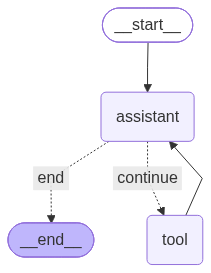

In [3]:
# 创建图
builder = StateGraph(MessagesState)

# 添加节点
builder.add_node("assistant", assistant)
builder.add_node("tool", tool_node)

# 添加边
builder.add_edge(START, "assistant")

# 添加条件边
builder.add_conditional_edges(
    "assistant",
    should_continue,
    {
        "continue": "tool",
        "end": END,
    },
)

# 添加边：调用工具节点后回到assistant
builder.add_edge("tool", "assistant")

# 编译图
my_graph = builder.compile(name="my-graph")
my_graph

> **Note**
>
> 有向图分为：
>
> - 有向无环图（DAG）
> - 有向循环图（DCG）

从可视化结果可以看出，助手节点 `assistant` 与工具节点 `tool` 之间存在循环调用。因此，我们创建的是 **有向循环图**。下面来看一下，当询问上海天气时，工作流的运行过程。

In [ ]:
# 调用图
response = my_graph.invoke(
    {"messages": [HumanMessage(content="上海天气怎么样？")]}, version="v2"
).value
for message in response["messages"]:
    message.pretty_print()

## 二、节点级容错（LangGraph 1.2）

真实工作流中的模型、数据库和远程 API 都可能超时或暂时失败。LangGraph 1.2 把三层容错直接放进节点定义：

- `retry_policy`：只重试明确可恢复的异常
- `timeout`：为异步节点设置总运行时间或空闲超时
- `error_handler`：重试耗尽后更新状态，并可用 `Command` 路由到补偿节点

它们的固定顺序是“执行 → 重试 → 错误处理”。多个节点使用相同策略时，用 `set_node_defaults()` 统一配置；部署进程收到终止信号时，可用 `RunControl.request_drain()` 在当前 superstep 完成后保存检查点并安全退出。下面演示重试耗尽后进入补偿路径。

In [ ]:
from langgraph.errors import NodeError
from langgraph.types import Command, RetryPolicy
from typing_extensions import TypedDict


class ReliableState(TypedDict):
    status: str


def call_service(state: ReliableState) -> ReliableState:
    raise ConnectionError("temporary upstream failure")


def recover(state: ReliableState, error: NodeError) -> Command:
    return Command(update={"status": f"recovered from {type(error.error).__name__}"}, goto="finish")


def finish(state: ReliableState) -> ReliableState:
    return state


reliable_graph = (
    StateGraph(ReliableState)
    .add_node(
        "call_service",
        call_service,
        retry_policy=RetryPolicy(
            max_attempts=3,
            initial_interval=0.1,
            backoff_factor=1.0,
            jitter=False,
            retry_on=ConnectionError,
        ),
        error_handler=recover,
    )
    .add_node("finish", finish)
    .add_edge(START, "call_service")
    .compile()
)

output = reliable_graph.invoke({"status": "pending"}, version="v2")
output.value